# Bài 2 — Xử lý ảnh hình thái học

Foreground được biểu diễn bằng 255. Các phép NumPy dùng padding 255 khi co, 0 khi giãn; các giá trị này được dùng tương ứng khi đối chiếu OpenCV.


In [1]:
from pathlib import Path
import sys, time, csv, platform
import numpy as np
import cv2
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Run from repository root or notebooks/")
sys.path.insert(0, str(ROOT))
from src.morphology import (create_structuring_element, my_erosion, my_dilation,
                            my_opening, my_closing, boundary_extraction, hole_filling)
data = ROOT / "data" / "DIP3E_Original_Images_CH09"
files = {
    "wirebond": "Fig0905(a)(wirebond-mask).tif",
    "text_gaps": "Fig0907(a)(text_gaps_1_and_2_pixels).tif",
    "fingerprint": "Fig0911(a)(noisy_fingerprint).tif",
    "lincoln": "Fig0914(a)(licoln from penny).tif",
    "reflections": "Fig0916(a)(region-filling-reflections).tif",
}
images = {}
for name, filename in files.items():
    image = cv2.imread(str(data / filename), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(data / filename)
    images[name] = np.where(image > 127, 255, 0).astype(np.uint8)
    print(name, filename, image.shape, np.unique(image))
OUT = ROOT / "outputs" / "bai_2"
def figure(folder, filename, panels, titles, cols=4):
    path = OUT / folder
    path.mkdir(parents=True, exist_ok=True)
    rows = (len(panels) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3.7 * cols, 3.7 * rows), squeeze=False)
    for ax, image, title in zip(axes.flat, panels, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(path / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print(platform.platform(), "OpenCV", cv2.__version__, "NumPy", np.__version__)


wirebond Fig0905(a)(wirebond-mask).tif (486, 486) [  0 255]
text_gaps Fig0907(a)(text_gaps_1_and_2_pixels).tif (444, 508) [  0 255]
fingerprint Fig0911(a)(noisy_fingerprint).tif (238, 315) [  0 255]
lincoln Fig0914(a)(licoln from penny).tif (269, 221) [  0 255]
reflections Fig0916(a)(region-filling-reflections).tif (512, 512) [  0 255]
Windows-10-10.0.26300-SP0 OpenCV 5.0.0 NumPy 2.4.6


## 1. Đối chiếu bốn phép toán

Mỗi phép dùng cùng SE 3×3; phép mở và đóng được ghép từ các bước cơ bản để quy tắc biên ở từng bước thống nhất. Thời gian là trung vị ba lần chạy, sau một lượt khởi động.


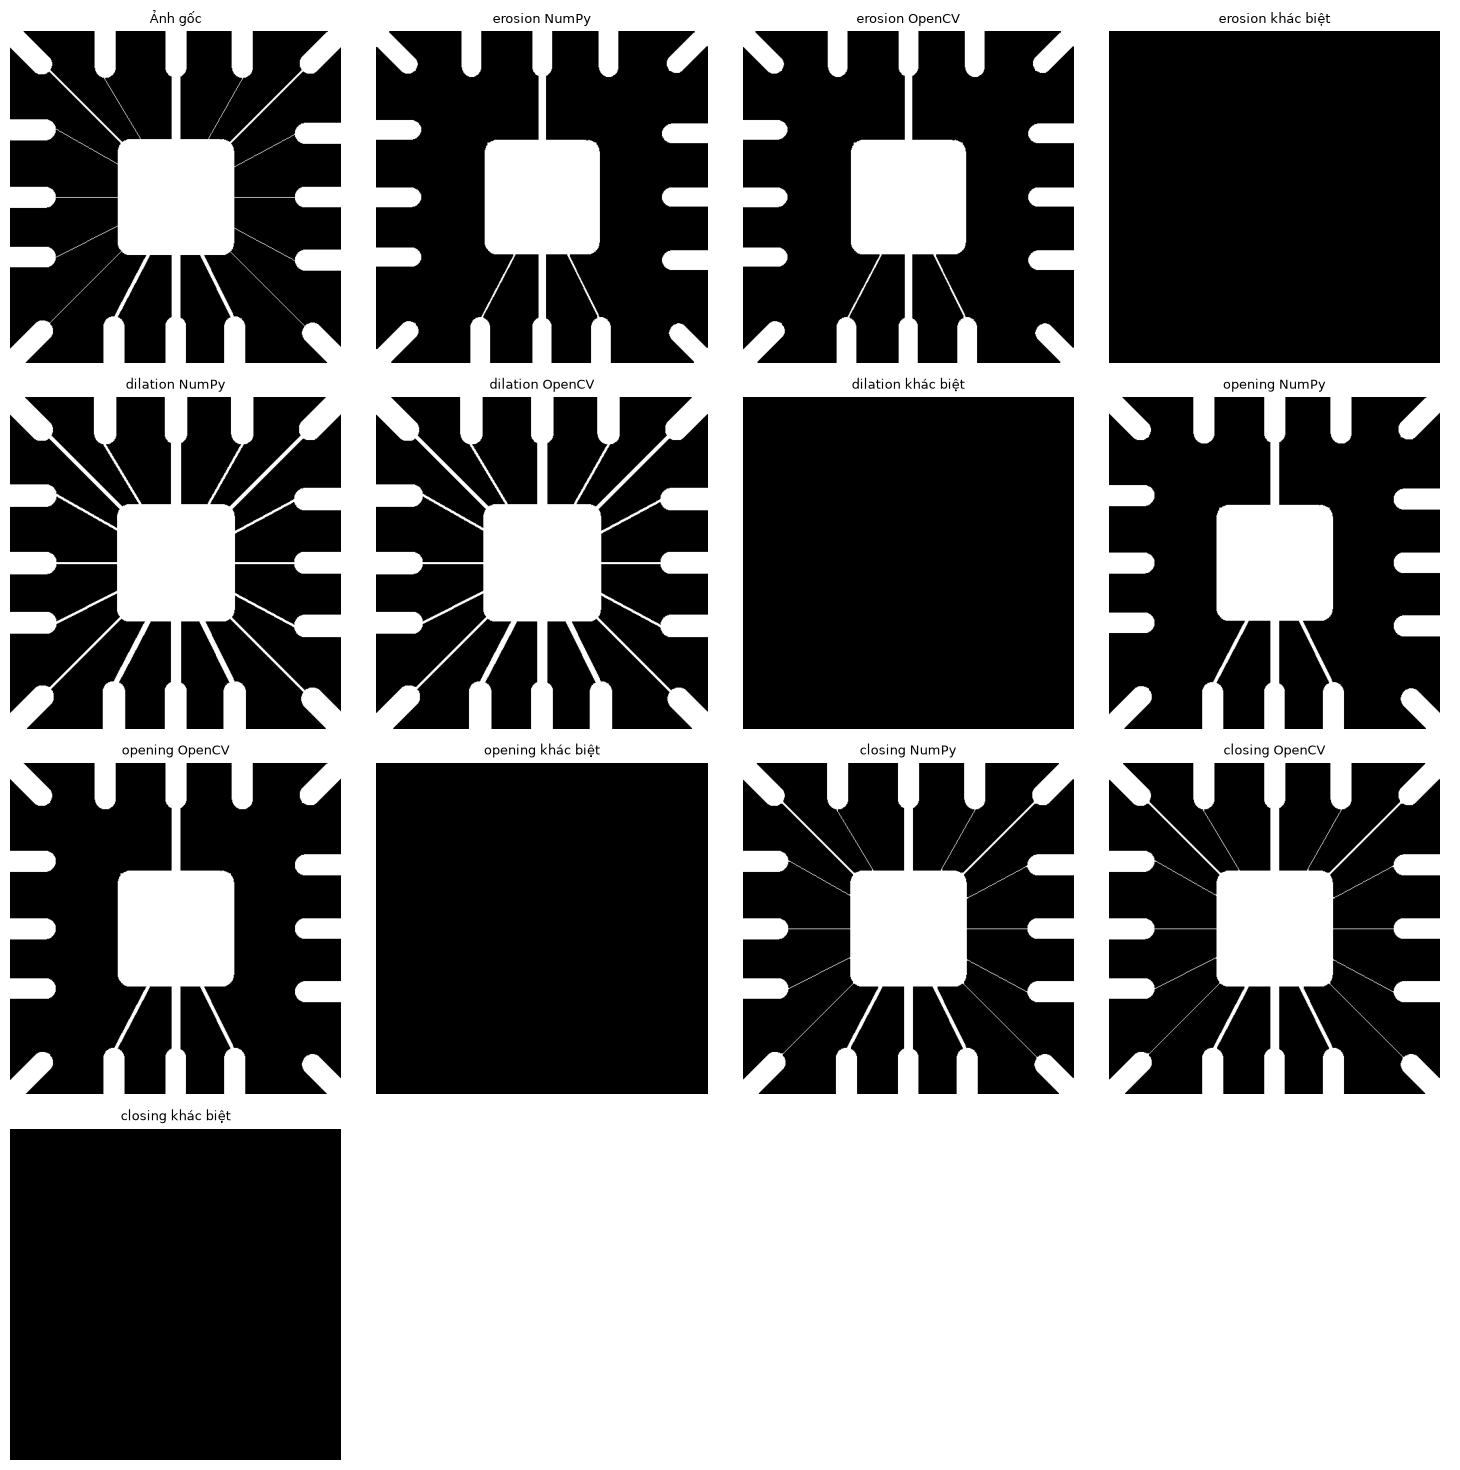

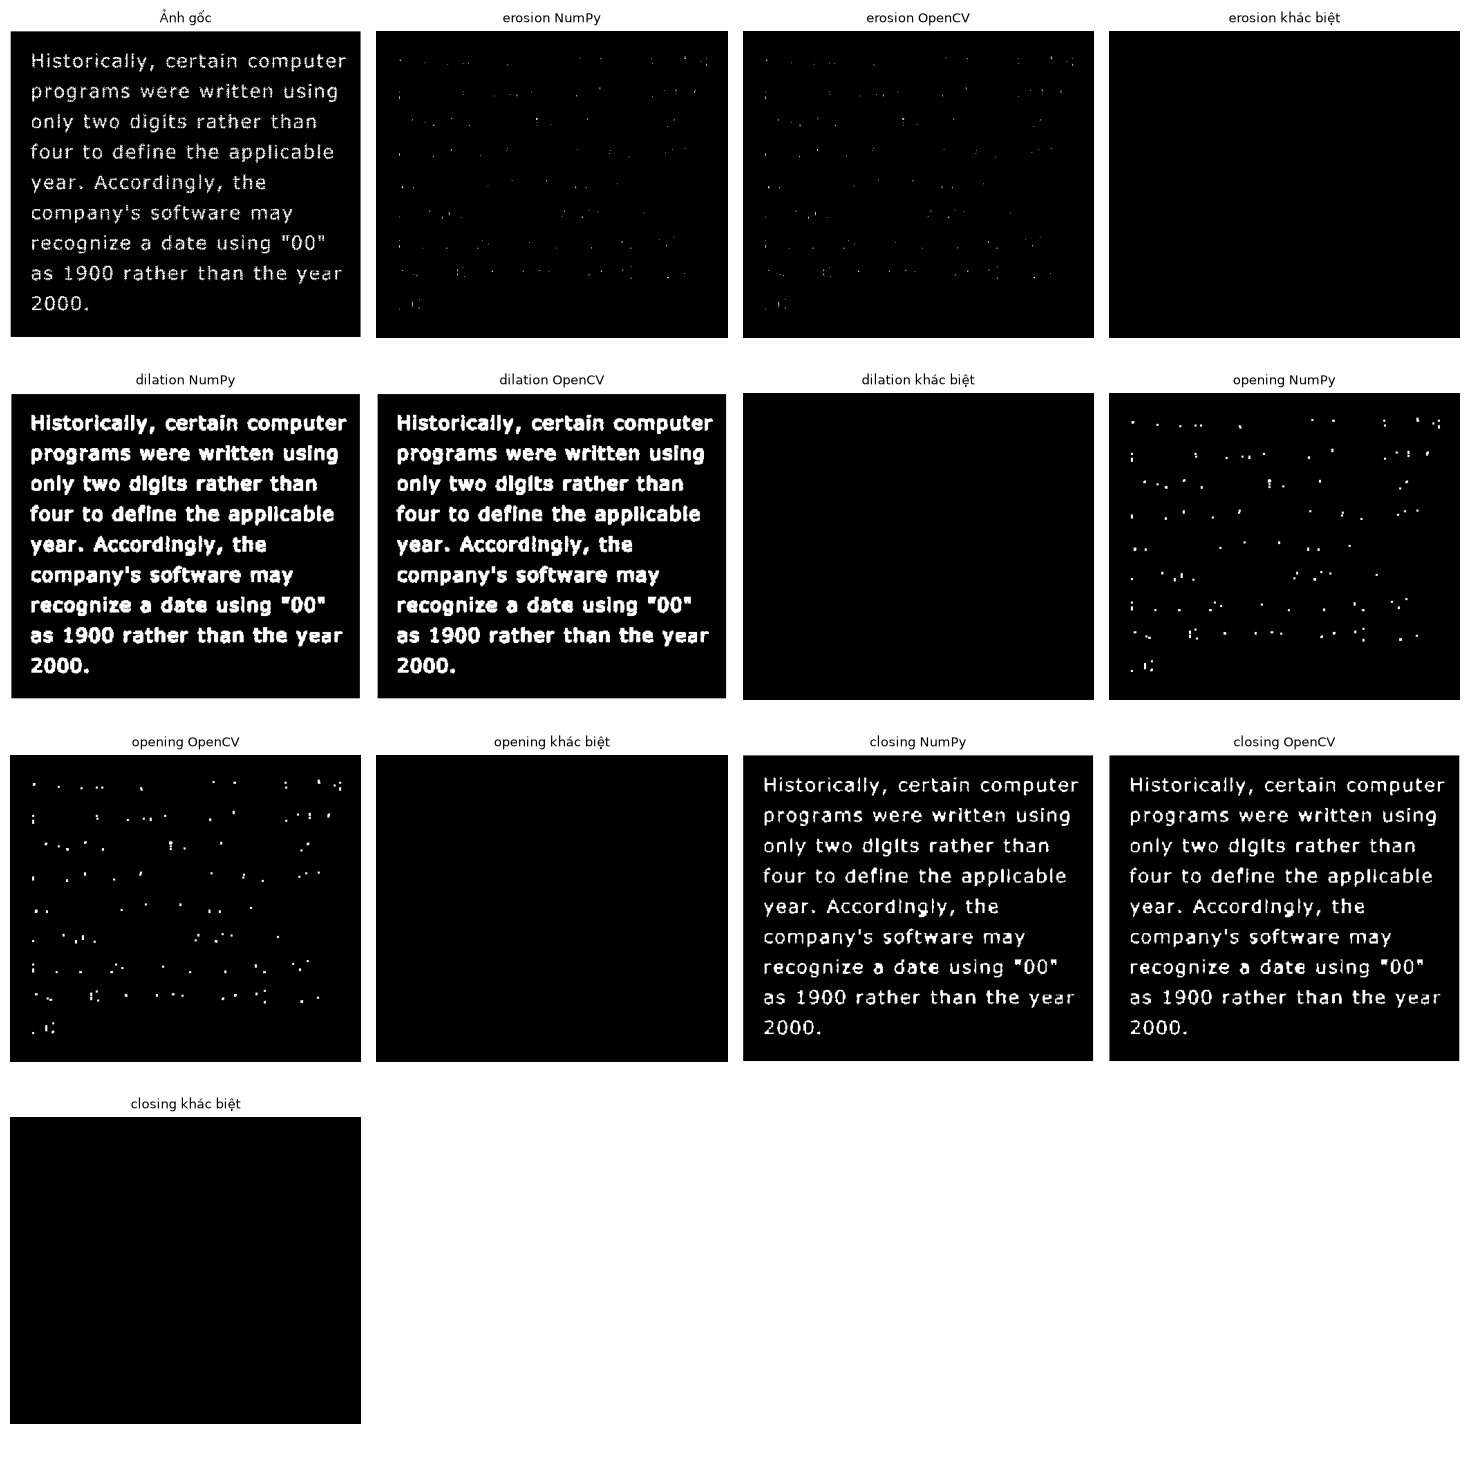

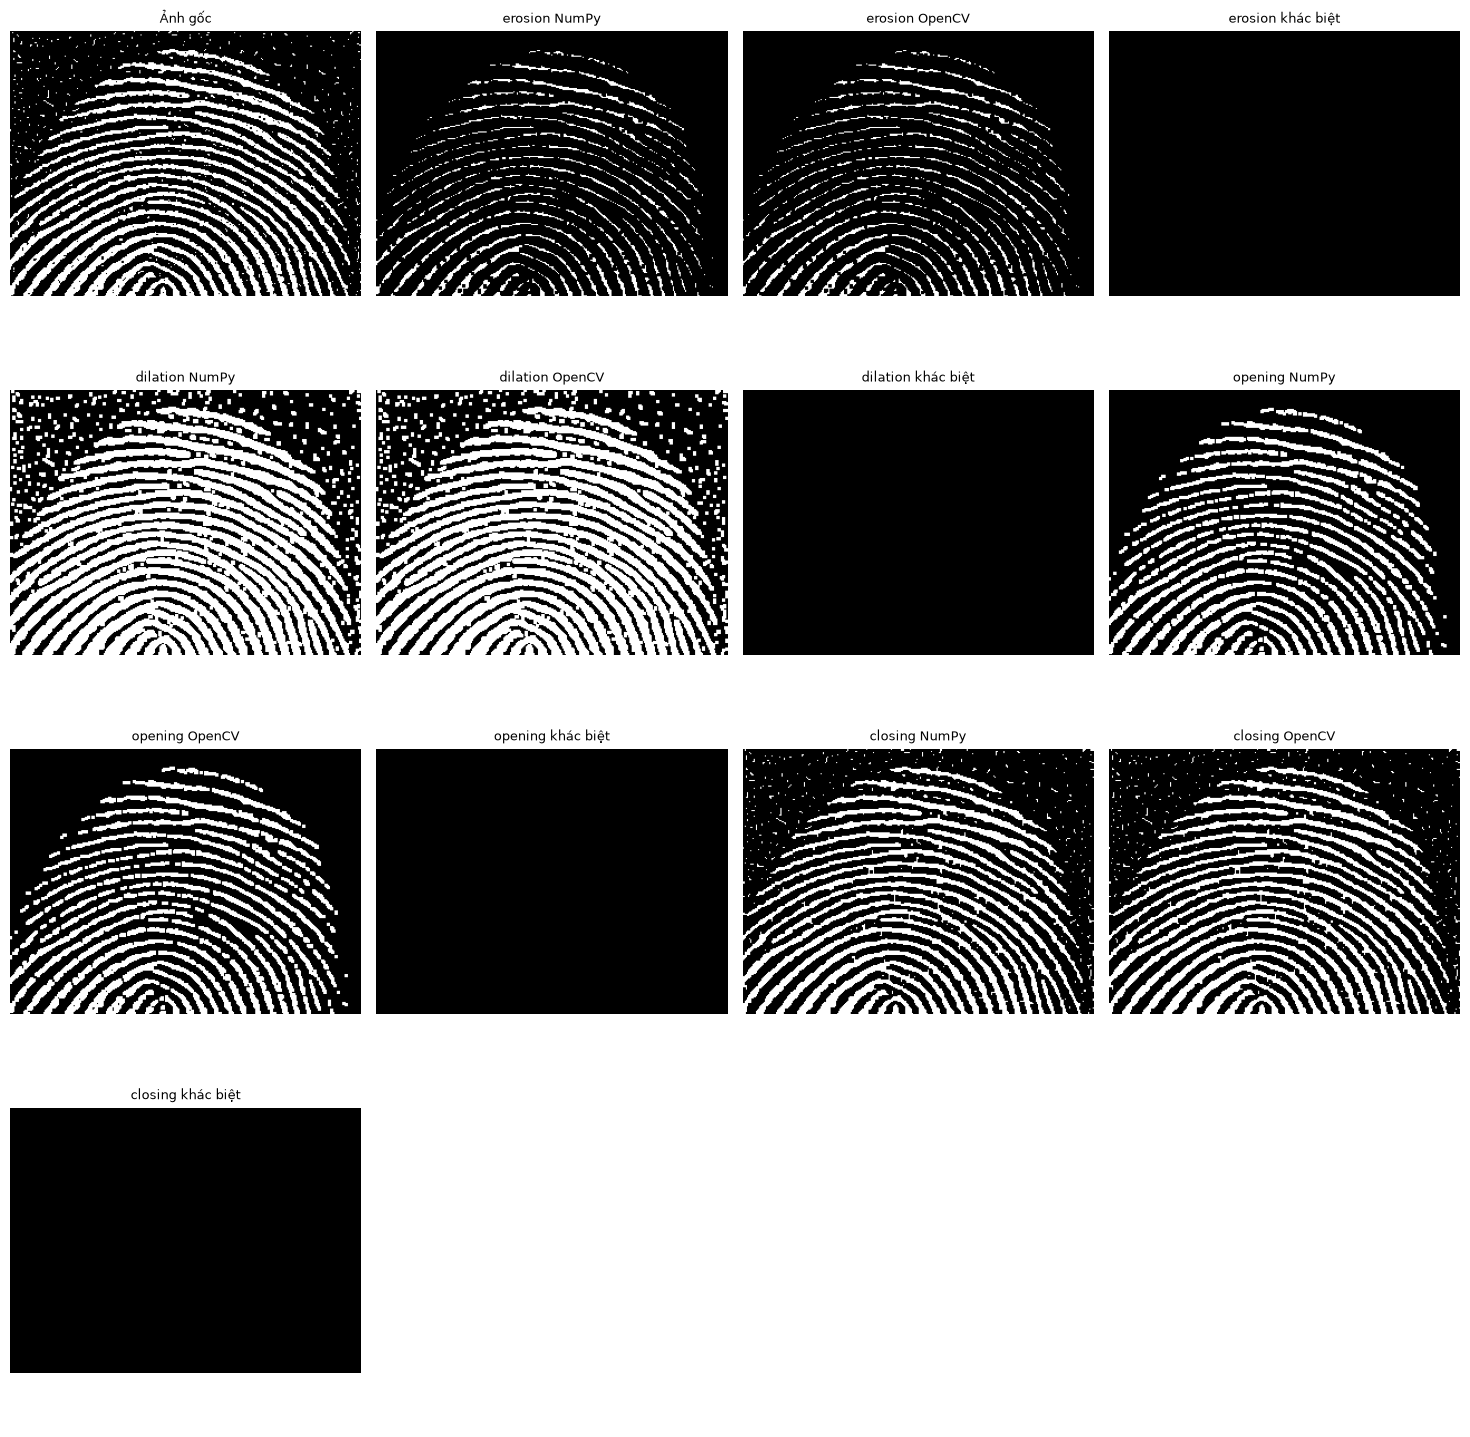

{'image': 'wirebond', 'operation': 'erosion', 'different_pixels': 0, 'max_error': 0, 'numpy_ms': 0.7850999827496707, 'opencv_ms': 0.07750000804662704}
{'image': 'wirebond', 'operation': 'dilation', 'different_pixels': 0, 'max_error': 0, 'numpy_ms': 1.3855000142939389, 'opencv_ms': 0.07730000652372837}
{'image': 'wirebond', 'operation': 'opening', 'different_pixels': 0, 'max_error': 0, 'numpy_ms': 1.5278999926522374, 'opencv_ms': 0.15390000771731138}
{'image': 'wirebond', 'operation': 'closing', 'different_pixels': 0, 'max_error': 0, 'numpy_ms': 1.5571999829262495, 'opencv_ms': 0.15269999857991934}
{'image': 'text_gaps', 'operation': 'erosion', 'different_pixels': 0, 'max_error': 0, 'numpy_ms': 0.7744999602437019, 'opencv_ms': 0.07839995669201016}
{'image': 'text_gaps', 'operation': 'dilation', 'different_pixels': 0, 'max_error': 0, 'numpy_ms': 0.7547999848611653, 'opencv_ms': 0.07780001033097506}
{'image': 'text_gaps', 'operation': 'opening', 'different_pixels': 0, 'max_error': 0, 'num

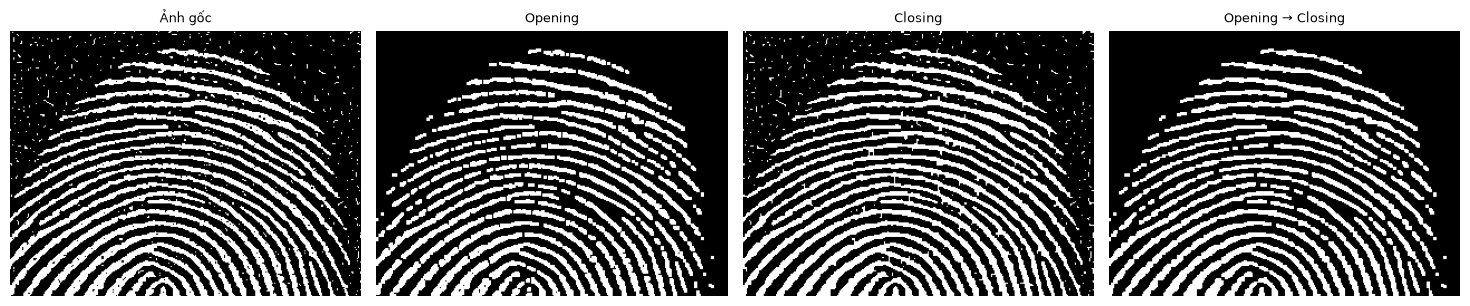

In [2]:
se = create_structuring_element("RECT", 3)
def cv_erode(a, k):
    return cv2.erode(a, k, borderType=cv2.BORDER_CONSTANT, borderValue=255)
def cv_dilate(a, k):
    return cv2.dilate(a, k, borderType=cv2.BORDER_CONSTANT, borderValue=0)
ops = {
    "erosion": (my_erosion, cv_erode),
    "dilation": (my_dilation, cv_dilate),
    "opening": (my_opening, lambda a, k: cv_dilate(cv_erode(a, k), k)),
    "closing": (my_closing, lambda a, k: cv_erode(cv_dilate(a, k), k)),
}
measurements = []
for name in ("wirebond", "text_gaps", "fingerprint"):
    image = images[name]
    panels, titles = [image], ["Ảnh gốc"]
    for op, (own, reference) in ops.items():
        actual, expected = own(image, se), reference(image, se)
        diff = cv2.absdiff(actual, expected)
        timings = []
        for fn in (own, reference):
            fn(image, se)
            samples = []
            for _ in range(3):
                start = time.perf_counter()
                fn(image, se)
                samples.append((time.perf_counter() - start) * 1000)
            timings.append(float(np.median(samples)))
        measurements.append({"image": name, "operation": op, "different_pixels": int(np.count_nonzero(diff)),
                             "max_error": int(diff.max()), "numpy_ms": timings[0], "opencv_ms": timings[1]})
        panels.extend([actual, expected, diff])
        titles.extend([op + " NumPy", op + " OpenCV", op + " khác biệt"])
    figure("2.1_numpy_vs_opencv", f"2.1_{name}_input_vs_output_4_ops.png", panels, titles)
for row in measurements:
    print(row)
path = OUT / "2.1_numpy_vs_opencv" / "comparison.csv"
with path.open("w", encoding="utf-8-sig", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=measurements[0].keys())
    writer.writeheader()
    writer.writerows(measurements)
assert all(row["different_pixels"] == 0 for row in measurements)
fp = images["fingerprint"]
opening = my_opening(fp, se)
closing = my_closing(fp, se)
figure("2.1_numpy_vs_opencv", "2.1_fingerprint_input_vs_output_denoise.png",
       [fp, opening, closing, my_closing(opening, se)],
       ["Ảnh gốc", "Opening", "Closing", "Opening → Closing"])


## 2. Khảo sát phần tử cấu trúc

Mỗi hình thay đổi một nhóm tham số. Theo dõi các nét bị mất, nối liền và các chữ bị dính.


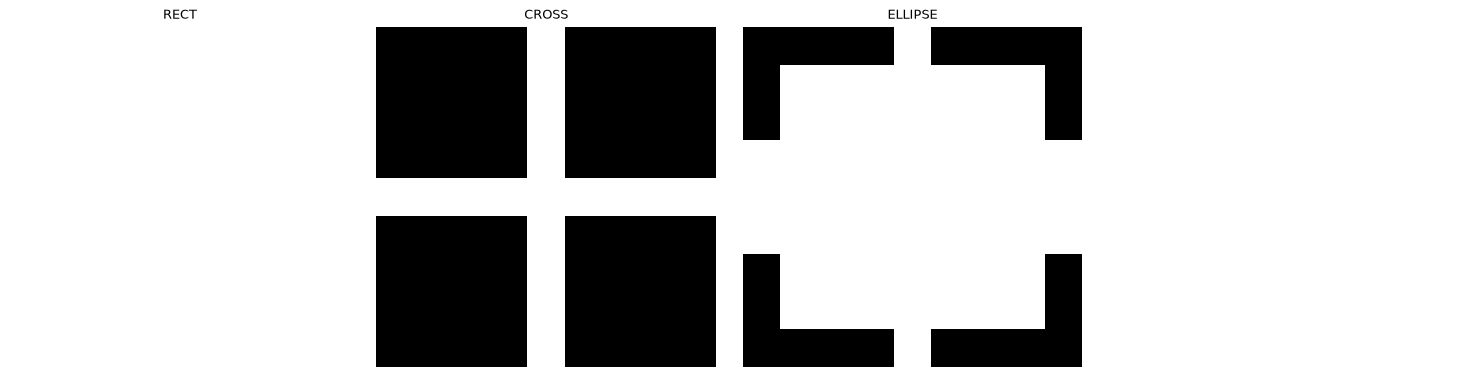

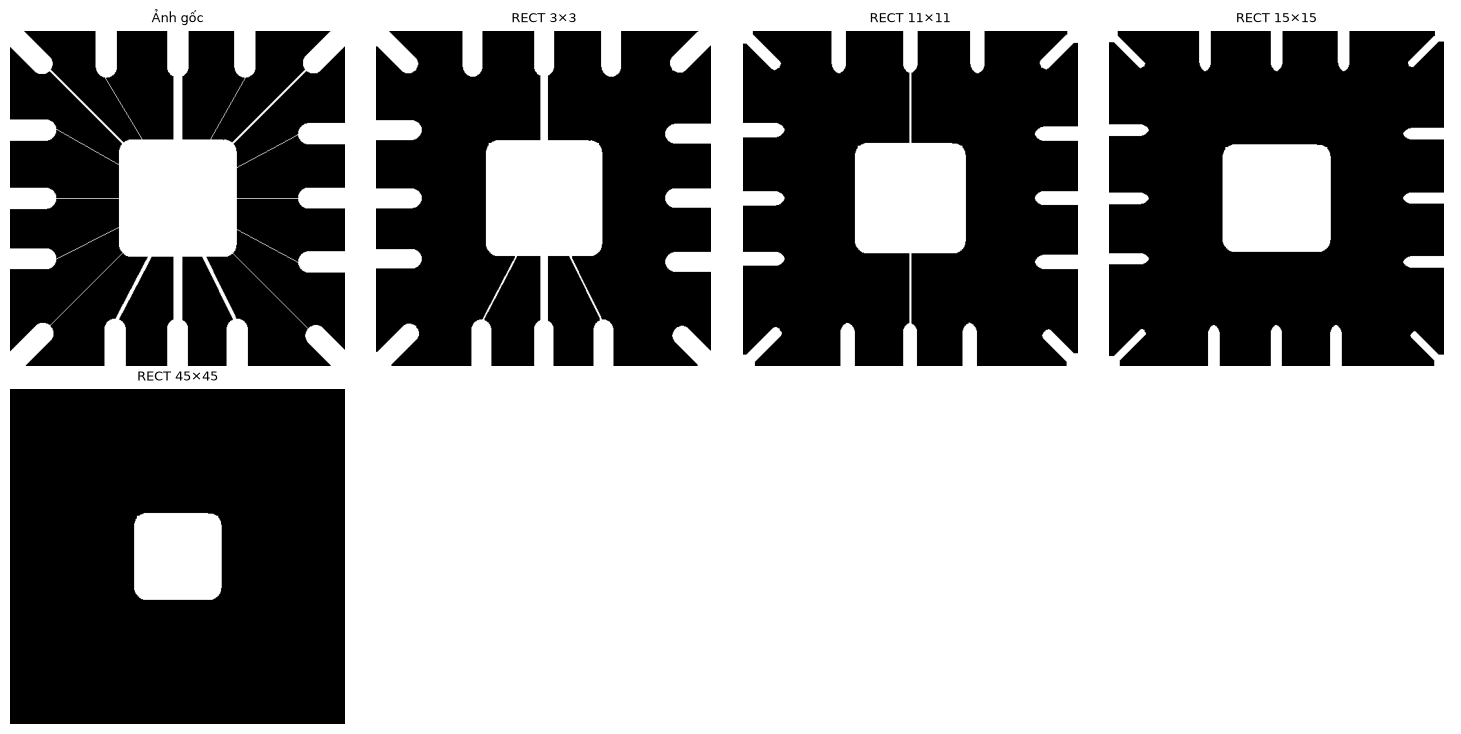

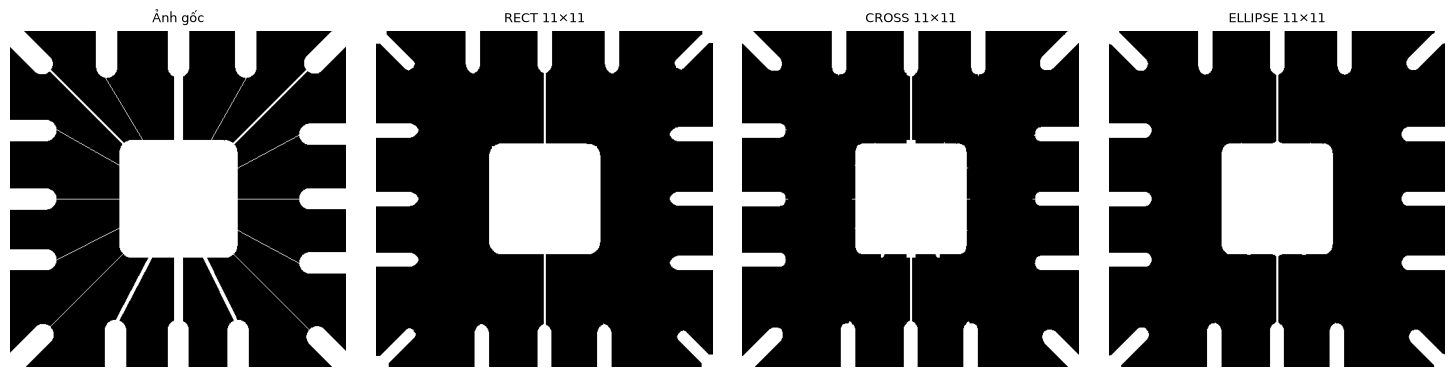

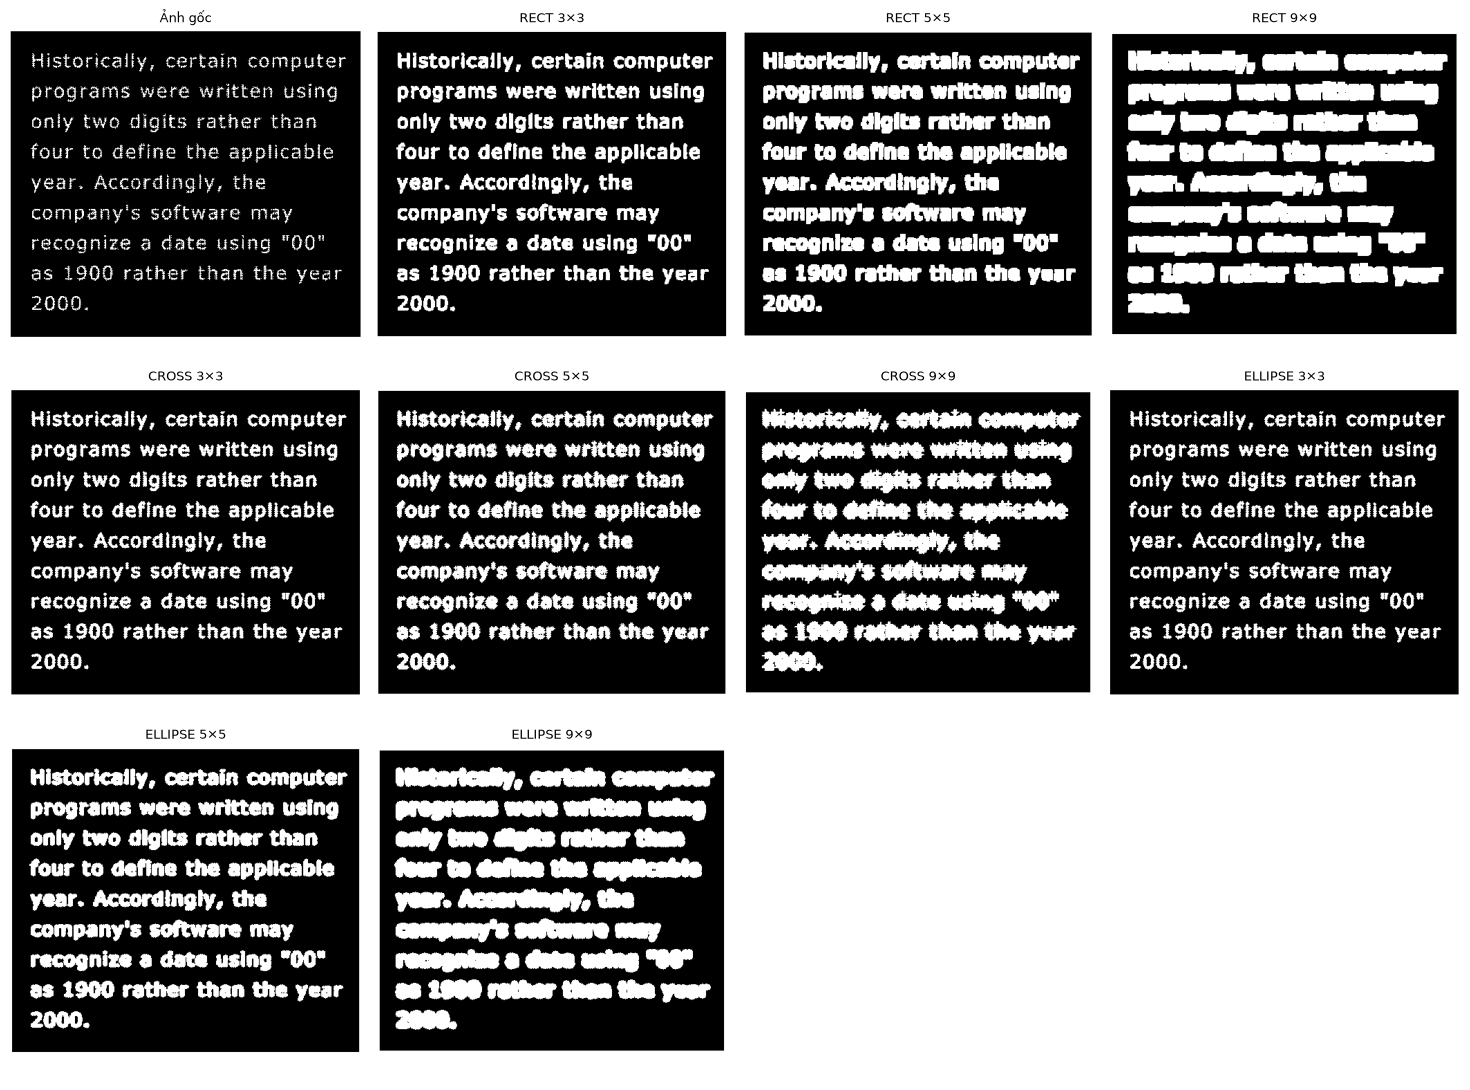

In [3]:
shapes = ("RECT", "CROSS", "ELLIPSE")
figure("2.2_structuring_elements", "2.2_se_shapes_and_sizes_visual.png",
       [create_structuring_element(shape, 9) * 255 for shape in shapes], list(shapes))
wire = images["wirebond"]
sizes = (3, 11, 15, 45)
figure("2.2_structuring_elements", "2.2_wirebond_input_vs_output_erosion_sizes.png",
       [wire] + [my_erosion(wire, create_structuring_element("RECT", k)) for k in sizes],
       ["Ảnh gốc"] + [f"RECT {k}×{k}" for k in sizes])
figure("2.2_structuring_elements", "2.2_wirebond_input_vs_output_erosion_shapes.png",
       [wire] + [my_erosion(wire, create_structuring_element(shape, 11)) for shape in shapes],
       ["Ảnh gốc"] + [f"{shape} 11×11" for shape in shapes])
text = images["text_gaps"]
figure("2.2_structuring_elements", "2.2_text_gaps_input_vs_output_dilation_shapes_sizes.png",
       [text] + [my_dilation(text, create_structuring_element(shape, k)) for shape in shapes for k in (3, 5, 9)],
       ["Ảnh gốc"] + [f"{shape} {k}×{k}" for shape in shapes for k in (3, 5, 9)])


## 3. Trích biên và làm đầy lỗ

Biên trong được tính bằng A trừ ảnh co. Với hole filling, nền được lan từ biên ảnh theo liên thông 4; các vùng nền không tới được là lỗ.


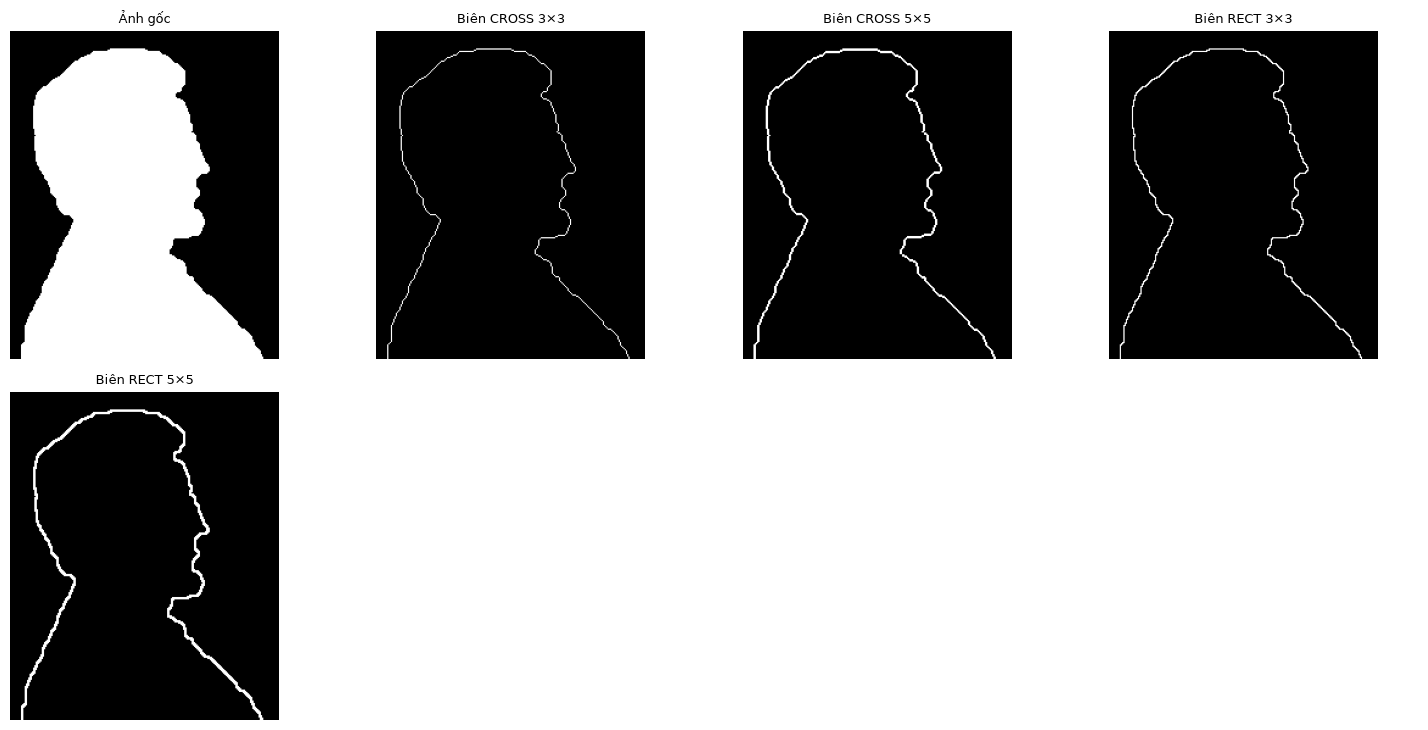

Hole filling: pixel thêm = 6322 ; pixel khác SciPy = 0


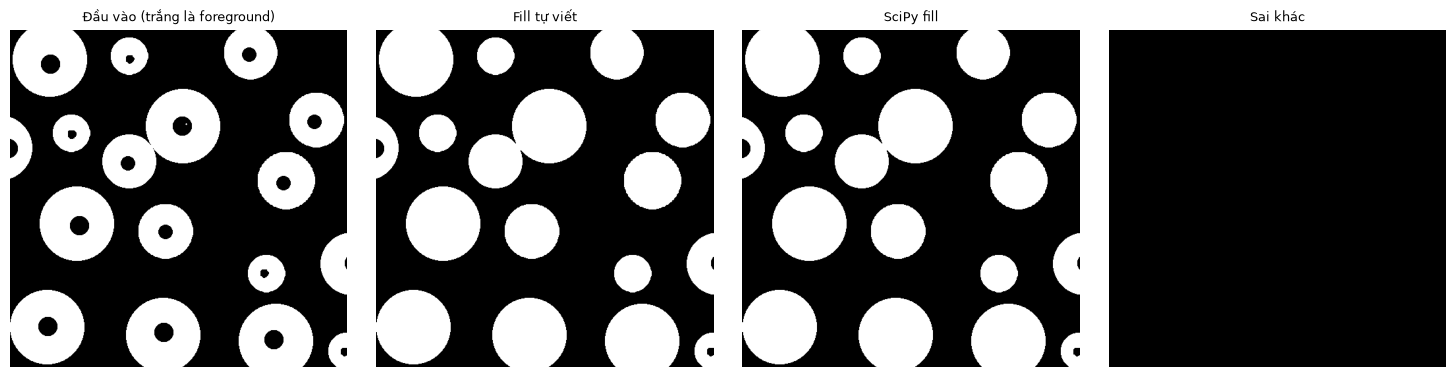

In [4]:
lincoln = images["lincoln"]
figure("2.3_advanced_algorithms", "2.3_lincoln_input_vs_output_boundary.png",
       [lincoln] + [boundary_extraction(lincoln, create_structuring_element(shape, k))
                    for shape in ("CROSS", "RECT") for k in (3, 5)],
       ["Ảnh gốc"] + [f"Biên {shape} {k}×{k}" for shape in ("CROSS", "RECT") for k in (3, 5)])
reflections = images["reflections"]
filled = hole_filling(reflections, create_structuring_element("CROSS", 3))
from scipy.ndimage import binary_fill_holes
reference = binary_fill_holes(reflections != 0).astype(np.uint8) * 255
difference = cv2.absdiff(filled, reference)
print("Hole filling: pixel thêm =", np.count_nonzero(filled) - np.count_nonzero(reflections),
      "; pixel khác SciPy =", np.count_nonzero(difference))
figure("2.3_advanced_algorithms", "2.3_reflections_input_vs_output_hole_filling.png",
       [reflections, filled, reference, difference],
       ["Đầu vào (trắng là foreground)", "Fill tự viết", "SciPy fill", "Sai khác"])
assert np.array_equal(filled, reference)


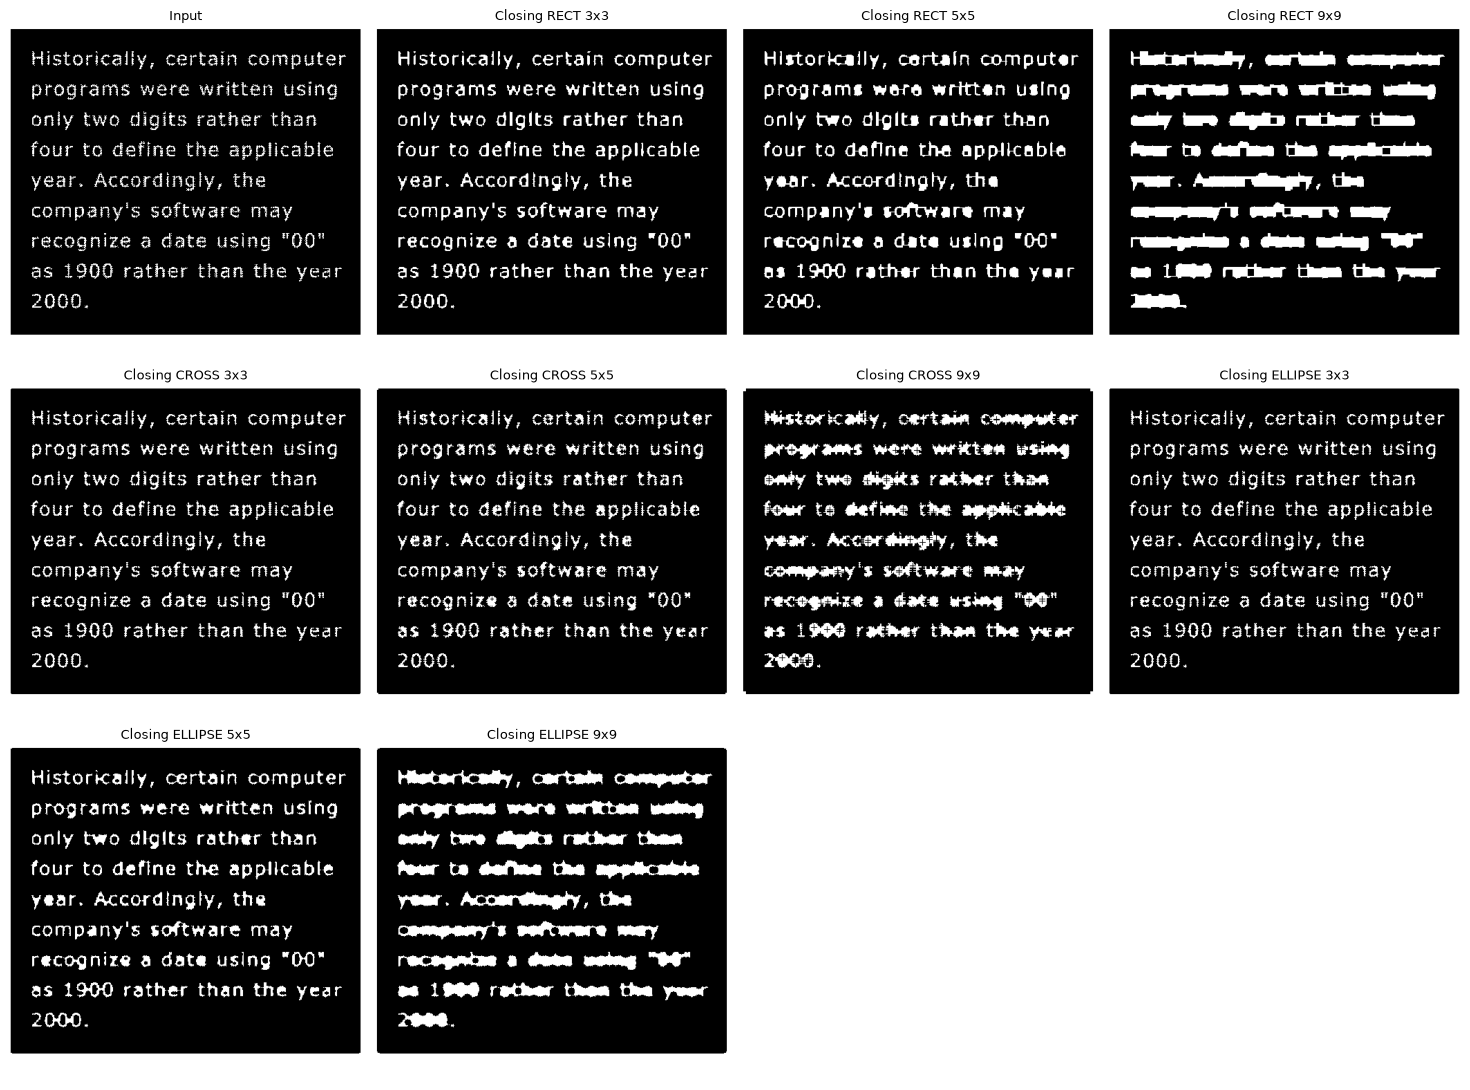

In [5]:
text = images["text_gaps"]
panels=[text]; titles=["Input"]
for shape in ("RECT","CROSS","ELLIPSE"):
    for k in (3,5,9):
        kernel=create_structuring_element(shape,k)
        panels.append(my_closing(text,kernel))
        titles.append(f"Closing {shape} {k}x{k}")
figure("2.2_structuring_elements","2.2_text_gaps_closing_shapes_sizes.png",panels,titles)


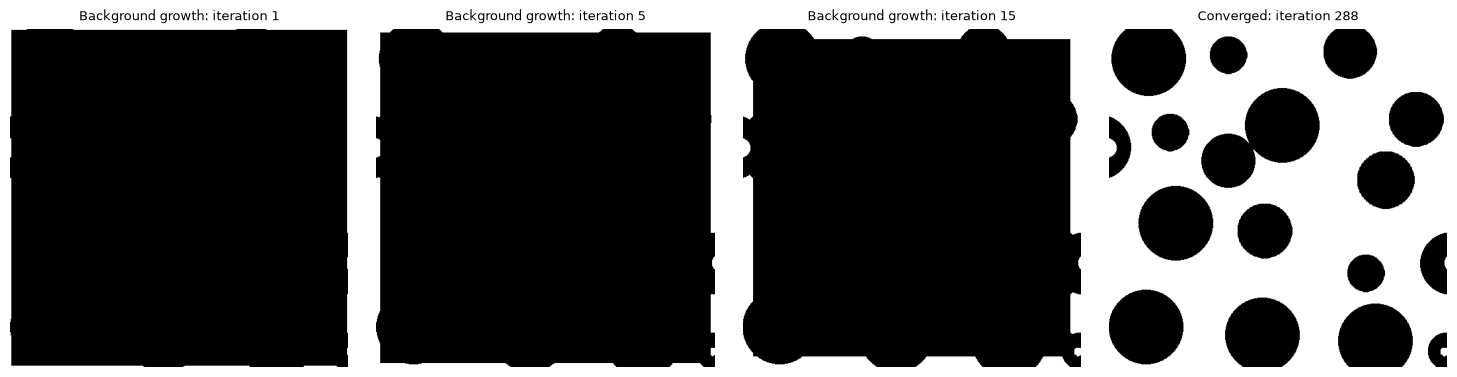

In [6]:
foreground = reflections != 0
background = ~foreground
reached = np.zeros_like(foreground, dtype=np.uint8)
reached[0,:] = background[0,:]; reached[-1,:] = background[-1,:]
reached[:,0] = background[:,0]; reached[:,-1] = background[:,-1]
kernel = create_structuring_element("CROSS",3)
snapshots=[]; titles=[]
for iteration in range(1, 2000):
    updated = cv2.dilate(reached, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0) & background
    if iteration in (1,5,15):
        snapshots.append(updated.astype(np.uint8)*255); titles.append(f"Background growth: iteration {iteration}")
    if np.array_equal(updated,reached):
        snapshots.append(updated.astype(np.uint8)*255); titles.append(f"Converged: iteration {iteration}")
        break
    reached=updated
else:
    raise RuntimeError("Background growth did not converge")
figure("2.3_advanced_algorithms","2.3_reflections_fill_iterations.png",snapshots,titles)


## Hướng dẫn nhận xét

Dựa vào bảng sai khác, thời gian đo và các hình để mô tả tác động của SE. Kết quả thời gian phụ thuộc máy và kích thước ảnh. Chọn hình dễ đọc, ghi tham số và bổ sung ảnh chụp màn hình cá nhân khi làm báo cáo.
